In [1]:


import mlflow
from datasets import Dataset
from dotenv import load_dotenv
from IPython.display import Image, display
from langchain_chroma import Chroma
from langchain_core.documents import Document
from langchain_core.prompts import ChatPromptTemplate
from langchain_openai import ChatOpenAI, OpenAIEmbeddings
from langchain_text_splitters import RecursiveCharacterTextSplitter
from langgraph.graph import END, START, StateGraph
from langgraph.graph.message import MessagesState
from mlflow import log_metrics, log_params
from pypdf import PdfReader
from ragas import aevaluate
from ragas.embeddings import LangchainEmbeddingsWrapper
from ragas.llms import LangchainLLMWrapper
from ragas.run_config import RunConfig

In [2]:
# mlflow.langchain.autolog()

tracking_uri = "http://127.0.0.1:5000"
mlflow.set_tracking_uri(tracking_uri)

experiment = mlflow.set_experiment("LangGraph RAG Observability with RAGAS")

experiment

<Experiment: artifact_location='mlflow-artifacts:/2', creation_time=1795423169181, effective_trace_archival_retention=None, experiment_id='2', last_update_time=1795423169181, lifecycle_stage='active', name='LangGraph RAG Observability with RAGAS', tags={}, trace_location=None, workspace='default'>

In [3]:
load_dotenv()

model = "gpt-5.6-sol"

llm = ChatOpenAI(
    model=model,
    #temperature=0.0,
    max_completion_tokens=500,
    timeout=60,
    reasoning_effort="low",
    max_retries=2,
    use_responses_api=False,
)

llm_judge = ChatOpenAI(
    model=model,
    #temperature=0.0,
    max_completion_tokens=3000,
    timeout=60,
    reasoning_effort="medium",
    max_retries=2,
    use_responses_api=False,
)

In [4]:
embeddings_fn = OpenAIEmbeddings(model="text-embedding-3-large")

In [5]:
with mlflow.start_run(run_name="rag_evaluation_using_ragas") as run:
    log_params(
        {
            "embeddings_model":embeddings_fn.model,
            "llm_model": llm.model_name,
            "llm_judge_model": llm_judge.model_name,
        }
    )
    print(run.info)

<RunInfo: artifact_uri='mlflow-artifacts:/2/faeee906ecd9459a8bfd2a141ff9684d/artifacts', end_time=None, experiment_id='2', lifecycle_stage='active', run_id='faeee906ecd9459a8bfd2a141ff9684d', run_name='rag_evaluation_using_ragas', start_time=1795426680330, status='RUNNING', user_id='AJ'>
🏃 View run rag_evaluation_using_ragas at: http://127.0.0.1:5000/#/experiments/2/runs/faeee906ecd9459a8bfd2a141ff9684d
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/2


In [6]:
mlflow_run_id = run.info.run_id

mlflow_run_id

'faeee906ecd9459a8bfd2a141ff9684d'

In [7]:
mflow_client = mlflow.tracking.MlflowClient()

In [8]:
mflow_client.get_run(mlflow_run_id)

<Run: data=<RunData: metrics={}, params={'embeddings_model': 'text-embedding-3-large',
 'llm_judge_model': 'gpt-5.6-sol',
 'llm_model': 'gpt-5.6-sol'}, tags={'mlflow.runName': 'rag_evaluation_using_ragas',
 'mlflow.source.name': 'EXERCISE_03_langgraph_rag_evaluation.ipynb',
 'mlflow.source.type': 'NOTEBOOK',
 'mlflow.user': 'AJ'}>, info=<RunInfo: artifact_uri='mlflow-artifacts:/2/faeee906ecd9459a8bfd2a141ff9684d/artifacts', end_time=1795426680396, experiment_id='2', lifecycle_stage='active', run_id='faeee906ecd9459a8bfd2a141ff9684d', run_name='rag_evaluation_using_ragas', start_time=1795426680330, status='FINISHED', user_id='AJ'>, inputs=<RunInputs: dataset_inputs=[], model_inputs=[]>, outputs=<RunOutputs: model_outputs=[]>>

In [9]:
vector_store = Chroma(
    collection_name="rag_demo",
    embedding_function=embeddings_fn,
    persist_directory="./chroma_langchain_db",
)

In [10]:
file_path = "data/exam_guide.pdf"

reader = PdfReader(file_path)

docs: list[Document] = []

for page in reader.pages:
    source = f"{file_path}"
    docs.append(Document(page_content=page.extract_text(), metadata={"source": source}))

print(f"Loaded {len(docs)} documentation pages.")

Loaded 3 documentation pages.


In [11]:
text_splitter = RecursiveCharacterTextSplitter(chunk_size=1000, chunk_overlap=200)
all_splits = text_splitter.split_documents(docs)

print(f"Split documentation into {len(all_splits)} chunks.")

Split documentation into 8 chunks.


In [12]:
vector_store.add_documents(documents=all_splits)

print(f"Indexed {len(all_splits)} chunks.")

Indexed 8 chunks.


In [13]:
class State(MessagesState):
    run_id: str
    question: str
    ground_truth: str
    documents: list[Document]
    answer: str
    evaluation: dict

In [14]:
def retrieve(state: State):
    question = state["question"]
    retrieved_docs = vector_store.similarity_search(question, k=3)
    return {"documents": retrieved_docs}

In [15]:
def augment(state: State):
    question = state["question"]
    documents = state["documents"]
    docs_content = "\n\n".join(doc.page_content for doc in documents)

    template = ChatPromptTemplate([
        ("system", "You are an assistant for question-answering tasks."),
        ("human", """Use the following pieces of retrieved context to answer the question.
                If you don't know the answer, just say that you don't know.
                Use three sentences maximum and keep the answer concise.
                \n# Question: \n-> {question}
                \n# Context: \n-> {context}
                \n# Answer: """),
    ])

    messages = template.invoke(
        {"context": docs_content, "question": question}
    ).to_messages()

    return {"messages": messages}

In [16]:
def generate(state: State):
    ai_message = llm.invoke(state["messages"])
    return {"answer": ai_message.content, "messages": ai_message}

In [17]:
async def evaluate_rag(state: State):
    question = state["question"]
    documents = state["documents"]
    answer = state["answer"]
    ground_truth = state["ground_truth"]
    dataset = Dataset.from_dict(
        {
            "question": [question],
            "answer": [answer],
            "contexts": [[doc.page_content for doc in documents]],
            "ground_truth": [ground_truth]
        }
    )

    judge = LangchainLLMWrapper(llm_judge, bypass_temperature=True, bypass_n=True)
    ragas_embeddings = LangchainEmbeddingsWrapper(embeddings_fn)

    evaluation_results = await aevaluate(
        dataset=dataset,
        # metrics=[Faithfulness(), ContextPrecision(), ContextRecall(), AnswerRelevancy()],
        llm=judge,
        embeddings=ragas_embeddings,
        run_config=RunConfig(timeout=180, max_retries=2, max_workers=4),
        raise_exceptions=True,
    )

    print(evaluation_results)

    # Log metrics in MLflow
    # The evaluation_results output value is a list
    # Example: evaluation_results["faithfulness"][0]
    with mlflow.start_run(state["run_id"]):
        
        log_metrics({
            "faithfulness": evaluation_results["faithfulness"][0],
            "context_precision": evaluation_results["context_precision"][0],
            "context_recall": evaluation_results["context_recall"][0],
            "answer_relevancy": evaluation_results["answer_relevancy"][0]
        })

    return {"evaluation": evaluation_results}

In [18]:
workflow = StateGraph(State)

workflow.add_node("retrieve", retrieve)
workflow.add_node("augment", augment)
workflow.add_node("generate", generate)
workflow.add_node("evaluate_rag", evaluate_rag)

workflow.add_edge(START, "retrieve")
workflow.add_edge("retrieve", "augment")
workflow.add_edge("augment", "generate")
workflow.add_edge("generate", "evaluate_rag")
workflow.add_edge("evaluate_rag", END)

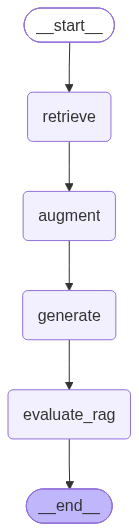

In [19]:
graph = workflow.compile()

display(
    Image(
        graph.get_graph().draw_mermaid_png()
    )
)

In [20]:
reference = [
    {
        "question": "What is The Langchain exam main requirement?",
        "ground_truth": """
            The main requirement is to take the 2-hour exam independently in a proctored environment.
            Join at least 15 minutes early for ID, room, and system checks; only approved LangChain resources are allowed—no AI assistants, general search, or second screens.
        """,
    }
]

In [21]:
output = await graph.ainvoke(
    {
        "question": reference[0]["question"],
        "ground_truth": reference[0]["ground_truth"],
        "run_id": mlflow_run_id
    }
)

C:\Users\amolj\AppData\Local\Temp\ipykernel_2532\1034028365.py:15: DeprecationWarning: LangchainLLMWrapper is deprecated and will be removed in a future version. Use llm_factory instead: from openai import OpenAI; from ragas.llms import llm_factory; llm = llm_factory('gpt-4o-mini', client=OpenAI(api_key='...'))
  judge = LangchainLLMWrapper(llm_judge, bypass_temperature=True, bypass_n=True)
C:\Users\amolj\AppData\Local\Temp\ipykernel_2532\1034028365.py:16: DeprecationWarning: LangchainEmbeddingsWrapper is deprecated and will be removed in a future version. Use the modern embedding providers instead: embedding_factory('openai', model='text-embedding-3-small', client=openai_client) or from ragas.embeddings import OpenAIEmbeddings, GoogleEmbeddings, HuggingFaceEmbeddings
  ragas_embeddings = LangchainEmbeddingsWrapper(embeddings_fn)
C:\Users\amolj\AppData\Local\Temp\ipykernel_2532\1034028365.py:18: DeprecationWarning: aevaluate() is deprecated and will be removed in a future version. Use 

Evaluating:   0%|          | 0/4 [00:00<?, ?it/s]

c:\Udacity\udacity-agentic-ai-engineer-with-langchain-and-langgraph\.venv\Lib\site-packages\langchain_openai\chat_models\base.py:566: UserWarning: Unexpected type for token usage: <class 'NoneType'>
  warnings.warn(f"Unexpected type for token usage: {type(new_usage)}")


{'answer_relevancy': 0.5194, 'context_precision': 1.0000, 'faithfulness': 1.0000, 'context_recall': 1.0000}
🏃 View run rag_evaluation_using_ragas at: http://127.0.0.1:5000/#/experiments/2/runs/faeee906ecd9459a8bfd2a141ff9684d
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/2


In [22]:
output

{'messages': [SystemMessage(content='You are an assistant for question-answering tasks.', additional_kwargs={}, response_metadata={}, id='56eeed20-b383-4943-a89d-a5d47240c208'),
  HumanMessage(content="Use the following pieces of retrieved context to answer the question.\n                If you don't know the answer, just say that you don't know.\n                Use three sentences maximum and keep the answer concise.\n                \n# Question: \n-> What is The Langchain exam main requirement?\n                \n# Context: \n-> CERTIFICATION · EXAM GUIDE\nLangChain Certified Agent Engineer\nExam guide: format, rules, and what each section covers.\nARRIVE EARLY\nPlease join your exam session at least 15 minutes before your scheduled start time. This window is used for ID check, room scan, and\nsystem veriﬁcation with your proctor.\nIf you join more than 10 minutes after your scheduled start time you will be marked as a no-show and will need to reschedule the\nexam at full cost.\nTh

In [23]:
mflow_client.get_run(mlflow_run_id)

<Run: data=<RunData: metrics={'answer_relevancy': 0.5194246266210317,
 'context_precision': 0.9999999999666667,
 'context_recall': 1.0,
 'faithfulness': 1.0}, params={'embeddings_model': 'text-embedding-3-large',
 'llm_judge_model': 'gpt-5.6-sol',
 'llm_model': 'gpt-5.6-sol'}, tags={'mlflow.runName': 'rag_evaluation_using_ragas',
 'mlflow.source.name': 'EXERCISE_03_langgraph_rag_evaluation.ipynb',
 'mlflow.source.type': 'NOTEBOOK',
 'mlflow.user': 'AJ'}>, info=<RunInfo: artifact_uri='mlflow-artifacts:/2/faeee906ecd9459a8bfd2a141ff9684d/artifacts', end_time=1795426712044, experiment_id='2', lifecycle_stage='active', run_id='faeee906ecd9459a8bfd2a141ff9684d', run_name='rag_evaluation_using_ragas', start_time=1795426680330, status='FINISHED', user_id='AJ'>, inputs=<RunInputs: dataset_inputs=[], model_inputs=[]>, outputs=<RunOutputs: model_outputs=[]>>

In [25]:
output["answer"]

'The main requirement is to take the two-hour exam solo under live proctoring, following the room, camera, screen-sharing, and ID-check rules. Only whitelisted LangChain resources are allowed; AI tools, web searches, second screens, and outside communication are prohibited.'

In [26]:
output["evaluation"]

{'answer_relevancy': 0.5194, 'context_precision': 1.0000, 'faithfulness': 1.0000, 'context_recall': 1.0000}

In [28]:
print(output["ground_truth"])


            The main requirement is to take the 2-hour exam independently in a proctored environment.
            Join at least 15 minutes early for ID, room, and system checks; only approved LangChain resources are allowed—no AI assistants, general search, or second screens.
        
